# Dipole Slot: HFSS Results

Plot the two CSV files in this folder using their original samples. Frequency is in GHz, impedance in ohms, and S11 is already in dB. Select **Run All** to update the plots.

Markers follow the HFSS screenshot. Z marker m1 lies between samples: linear interpolation gives 6.8528 ohms at 2.9746 GHz, versus 6.9364 in HFSS. The other marker values match to four decimal places.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

%matplotlib inline

f_s, s11 = np.loadtxt("dipole_slot_S_Parameter_Plot_1.csv", delimiter=",", skiprows=1, unpack=True)
f_z, re_z, im_z = np.loadtxt("dipole_slot_Z_Parameter_Plot.csv", delimiter=",", skiprows=1, unpack=True)

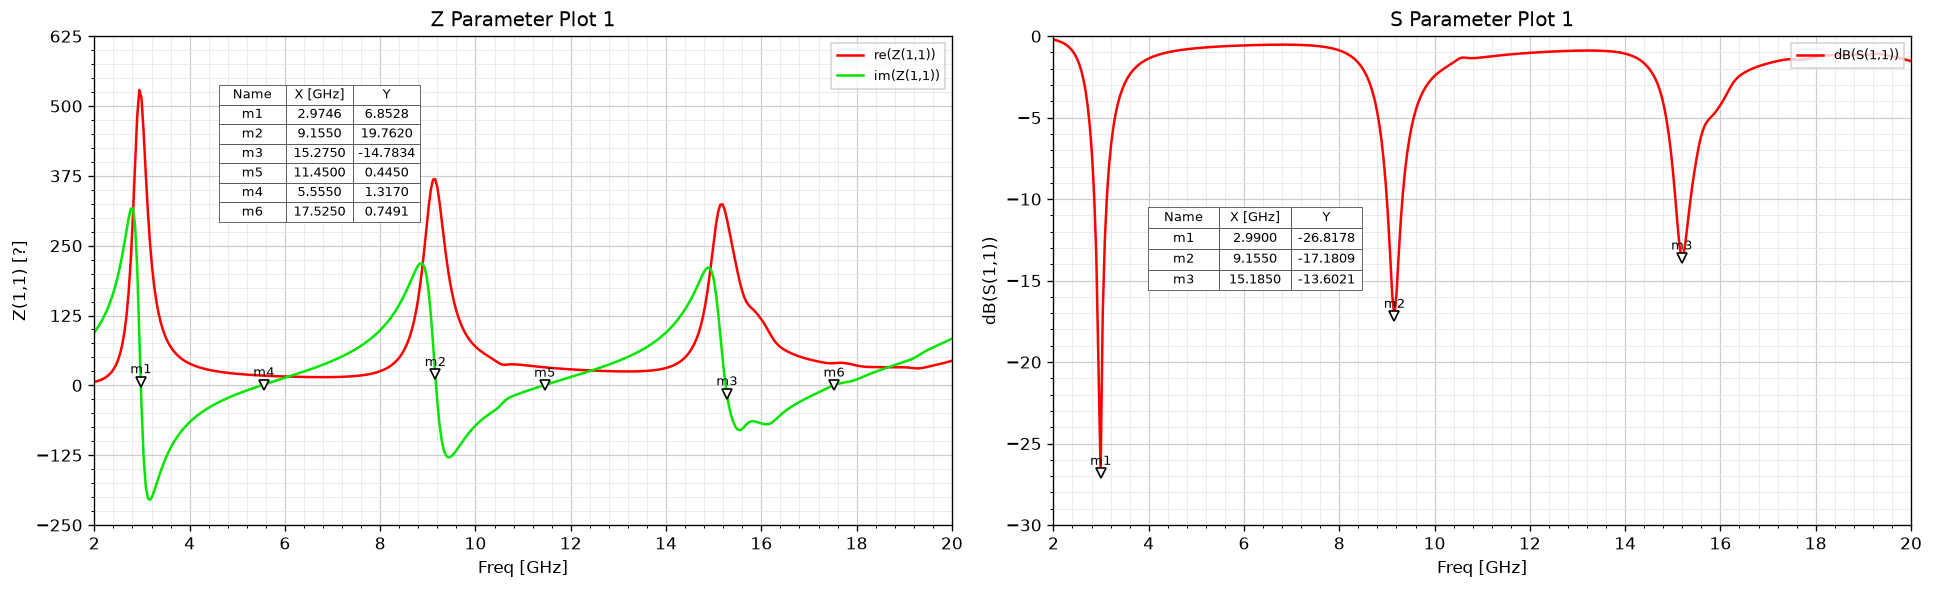

In [2]:
def mark(ax, f, y, points, box):
    rows = []
    for name, x in points:
        value = np.interp(x, f, y)
        ax.plot(x, value, "kv", mfc="white", ms=6)
        ax.annotate(name, (x, value), xytext=(0, 5), textcoords="offset points",
                    ha="center", fontsize=8)
        rows.append([name, f"{x:.4f}", f"{value:.4f}"])
    table = ax.table(cellText=rows, colLabels=["Name", "X [GHz]", "Y"],
                     cellLoc="center", bbox=box, zorder=5)
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    for cell in table.get_celld().values():
        cell.set_edgecolor("0.3")
        cell.set_linewidth(0.5)

fig, (az, a_s) = plt.subplots(1, 2, figsize=(16, 4.8), dpi=120, layout="constrained")
az.plot(f_z, re_z, "r", lw=1.5, label="re(Z(1,1))")
az.plot(f_z, im_z, color="#00e600", lw=1.5, label="im(Z(1,1))")
az.set(title="Z Parameter Plot 1", ylabel="Z(1,1) [?]", ylim=(-250, 625))
a_s.plot(f_s, s11, "r", lw=1.5, label="dB(S(1,1))")
a_s.set(title="S Parameter Plot 1", ylabel="dB(S(1,1))", ylim=(-30, 0))

for ax, y_step in [(az, 125), (a_s, 5)]:
    ax.set(xlim=(2, 20), xlabel="Freq [GHz]")
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(0.4))
    ax.yaxis.set_major_locator(MultipleLocator(y_step))
    ax.yaxis.set_minor_locator(MultipleLocator(y_step / 5))
    ax.set_axisbelow(True)
    ax.grid(which="major", color="0.8", lw=0.7)
    ax.grid(which="minor", color="0.91", lw=0.5)
    ax.legend(loc="upper right", fontsize=8, fancybox=False)

mark(az, f_z, im_z,
     [("m1", 2.9746), ("m2", 9.155), ("m3", 15.275),
      ("m5", 11.45), ("m4", 5.555), ("m6", 17.525)],
     [0.145, 0.62, 0.235, 0.28])
mark(a_s, f_s, s11, [("m1", 2.99), ("m2", 9.155), ("m3", 15.185)],
     [0.11, 0.48, 0.25, 0.17])
plt.show()